<img src="https://cdn.britannica.com/41/195741-050-E68CF3CA/California-united-states-locator-map.jpg" alt="California map" width="400"/>

# California Cities: a quick data analysis

In this notebook we use **Pandas** to inspect a table of California cities, **NumPy** to transform numerical data, and **Matplotlib** to find patterns with several charts.

### Topics
- Load and inspect a CSV dataset
- Select useful columns and check missing values
- Compare city populations and areas
- Build scatter plots, a ranked bar chart, and a histogram

**Question for the lesson:** Which cities are large, crowded, or geographically unusual?


> **Estimated time: 30 min**

## 1 · Import the tools

These three libraries cover the main workflow: tables, numerical operations, and visualizations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


%matplotlib inline

## 2 · Load and inspect the table

The CSV file should be in the same folder as this notebook. Start with a small preview before analyzing the data.

In [2]:
cities = pd.read_csv('california_cities.csv')
print('Rows and columns:', cities.shape)

Rows and columns: (482, 14)


In [3]:
cities.head()

,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


## 3 · Choose columns and check data quality

We keep the columns needed for today’s questions, And drop some columns that are not useful for this analysis.

In [4]:
print('Missing values:')
cities.isna().sum()

Missing values:


Unnamed: 0             0
city                   0
latd                   0
longd                  0
elevation_m           48
elevation_ft          12
population_total       0
area_total_sq_mi       2
area_land_sq_mi        0
area_water_sq_mi       1
area_total_km2         5
area_land_km2          4
area_water_km2         4
area_water_percent     5
dtype: int64

Convert elevation from feet to meters, and area from square miles to square kilometers if values are missing. 

We will keep the original values.

In [5]:
# cities["elevation_m"] = cities["elevation_ft"] * 0.3048
# cities["area_total_km2"] = cities["area_total_sq_mi"] * 2.58999
# cities["area_land_km2"] = cities["area_land_sq_mi"] * 2.58999
# cities["area_water_km2"] = cities["area_water_sq_mi"] * 2.58999

cities["elevation_m"] = cities["elevation_m"].fillna(cities["elevation_ft"] * 0.3048)
cities["area_total_km2"] = cities["area_total_km2"].fillna(cities["area_total_sq_mi"] * 2.58999)
cities["area_land_km2"] = cities["area_land_km2"].fillna(cities["area_land_sq_mi"] * 2.58999)
cities["area_water_km2"] = cities["area_water_km2"].fillna(cities["area_water_sq_mi"] * 2.58999)

In [6]:
print('Missing values:')
cities.isna().sum()

Missing values:


Unnamed: 0             0
city                   0
latd                   0
longd                  0
elevation_m            8
elevation_ft          12
population_total       0
area_total_sq_mi       2
area_land_sq_mi        0
area_water_sq_mi       1
area_total_km2         1
area_land_km2          0
area_water_km2         0
area_water_percent     5
dtype: int64

In [7]:
cities.drop(columns=['elevation_ft', 'area_total_sq_mi', 'area_land_sq_mi', 'area_water_sq_mi'], inplace=True)
cities.head()

/tmp/ipykernel_793919/92150201.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cities.drop(columns=['elevation_ft', 'area_total_sq_mi', 'area_land_sq_mi', 'area_water_sq_mi'], inplace=True)


,Unnamed: 0,city,latd,longd,elevation_m,population_total,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0000,31765,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0000,20330,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,10.0584,75467,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,13.1064,18969,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0000,83089,19.766,19.763,0.003,0.01


In [8]:
cities.describe().round(2)

,Unnamed: 0,latd,longd,elevation_m,population_total,area_total_km2,area_land_km2,area_water_km2,area_water_percent
count,482.00,482.00,482.00,474.00,482.00,481.00,482.00,482.00,477.00
mean,240.50,36.10,-119.84,173.07,64894.93,47.80,43.62,4.09,5.30
std,139.29,2.30,2.15,303.56,203204.10,94.06,84.67,24.55,14.66
min,0.00,32.58,-124.26,-54.86,1.00,0.81,0.81,0.00,0.00
25%,120.25,33.98,-121.95,21.00,10902.00,9.62,9.08,0.00,0.00
50%,240.50,36.20,-119.71,62.50,29057.50,23.55,21.66,0.08,0.34
75%,360.75,37.89,-117.98,158.50,66466.50,51.77,49.44,0.62,1.87
max,481.00,41.96,-114.60,2402.00,3884307.00,1302.00,1214.00,479.20,84.58


## 4 · Plot 1: a population map

Each dot is a city. 

Longitude and latitude position the city; dot size represents area, and color represents population. 

The logarithmic color scale helps us see both small and large cities.

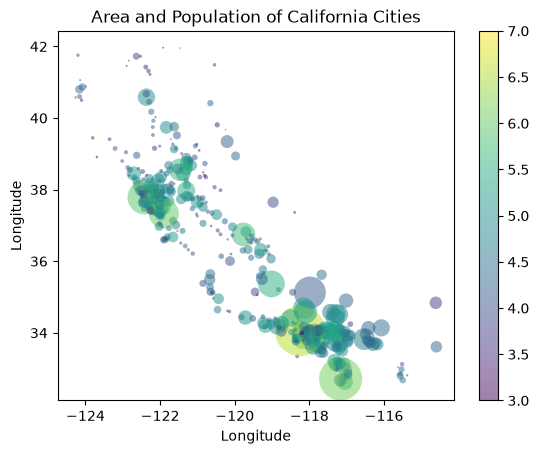

In [9]:
plt.scatter(
    cities['longd'],
    cities['latd'],
    cmap='viridis',
    c=np.log10(cities['population_total']),
    s=cities['area_total_km2'],
    linewidth=0, alpha=0.5
)

plt.xlabel('Longitude')
plt.ylabel('Longitude')
plt.colorbar()
plt.clim(3, 7)

plt.title("Area and Population of California Cities")
plt.show()

## 5 · Plot 2: the ten most populous cities

A horizontal bar chart is useful for ranking categories. Sorting the values makes the comparison easy to read.

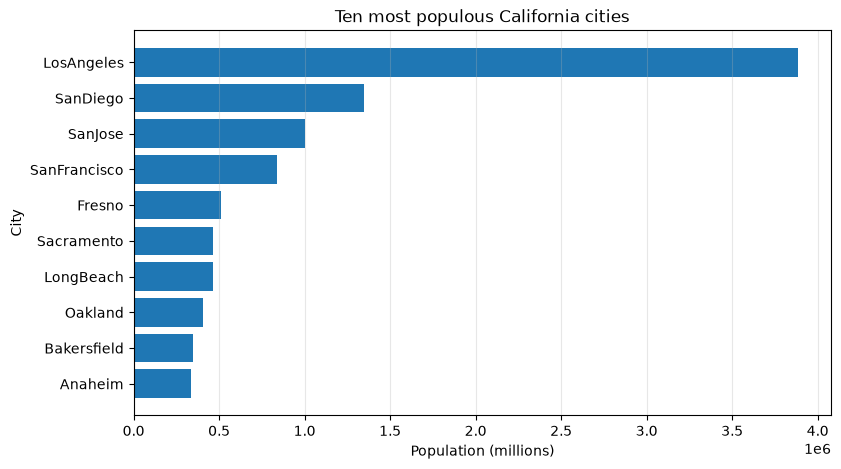

In [10]:
top_10 = cities.nlargest(10, 'population_total').sort_values('population_total')

plt.figure(figsize=(9, 5))
plt.barh(
    top_10['city'],
    top_10['population_total']
)
plt.xlabel('Population (millions)')
plt.ylabel('City')
plt.title('Ten most populous California cities')
plt.grid(axis='x', alpha=0.3)
plt.show()

## 6 · Plot 3: population and area

Does a larger city area mean a larger population? A scatter plot can reveal the relationship. We use logarithmic axes because the values vary widely.

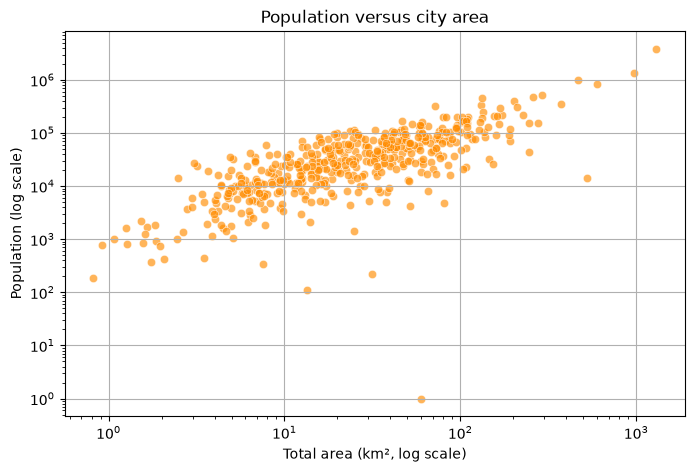

In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(
    cities['area_total_km2'],
    cities['population_total'],
    color='darkorange',
    alpha=0.65,
    edgecolors='white',
    linewidth=0.5
)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Total area (km², log scale)')
plt.ylabel('Population (log scale)')
plt.title('Population versus city area')
plt.grid()
plt.show()

## 8 · Plot 4: distribution of population density

Density helps us compare how concentrated cities are. A histogram shows the shape of the distribution, while the median gives us a typical value.

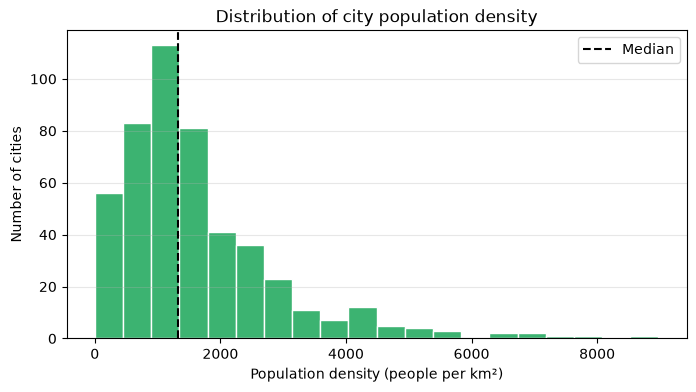

In [12]:
cities["population_density"] = cities["population_total"] / cities["area_land_km2"]

plt.figure(figsize=(8, 4))
plt.hist(cities['population_density'], bins=20, color='mediumseagreen', edgecolor='white')
plt.axvline(cities['population_density'].median(), color='black', linestyle='--', label='Median')
plt.xlabel('Population density (people per km²)')
plt.ylabel('Number of cities')
plt.title('Distribution of city population density')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

## 7 · Assignment: cities with the largest water area

**Question:** which 5 California cities have the largest water area?

The notebook already filled the missing `area_water_km2` values from the square-mile column (section 3), so we use `area_water_km2` directly. First, check its data type and missing values.

In [13]:
print('Data type:', cities['area_water_km2'].dtype)
print('Missing values:', cities['area_water_km2'].isna().sum())

# cities whose water area is still unknown (they cannot be ranked)
cities.loc[cities['area_water_km2'].isna(), ['city', 'area_water_km2', 'area_water_percent']]

Data type: float64
Missing values: 0


,city,area_water_km2,area_water_percent


The column is numeric (`float64`) and has **no missing values** after the fill in section 3 (in the raw CSV a few `area_water_km2` values were empty, e.g. San Francisco, and were recovered from `area_water_sq_mi`). It can be sorted directly.

In [14]:
top_water = cities.nlargest(5, 'area_water_km2')[['city', 'area_water_km2']]

# the city names are stored without spaces ("SanDiego"); add them back for readable labels
top_water['city'] = top_water['city'].str.replace(r'(?<=[a-z])(?=[A-Z])', ' ', regex=True)
top_water.reset_index(drop=True)

,city,area_water_km2
0,San Francisco,479.19995
1,San Diego,122.27000
2,Los Angeles,88.00000
3,Newport Beach,75.55700
4,Coronado,64.06200


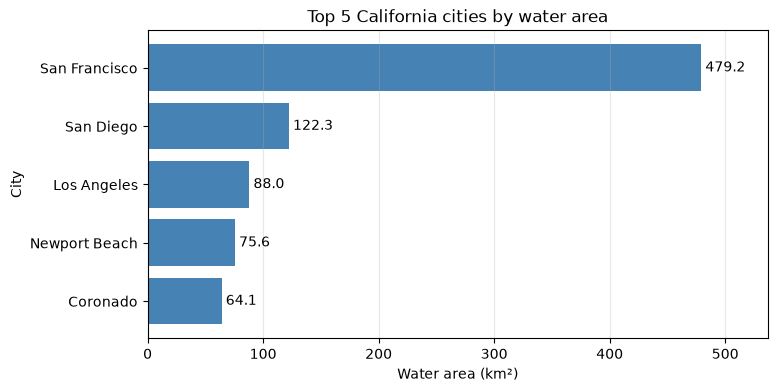

In [15]:
# barh draws the first row at the bottom, so sort ascending to put the largest on top
plot_data = top_water.sort_values('area_water_km2')

plt.figure(figsize=(8, 4))
bars = plt.barh(plot_data['city'], plot_data['area_water_km2'], color='steelblue')
plt.bar_label(bars, fmt='%.1f', padding=3)
plt.xlabel('Water area (km²)')
plt.ylabel('City')
plt.title('Top 5 California cities by water area')
plt.xlim(0, plot_data['area_water_km2'].max() * 1.12)
plt.grid(axis='x', alpha=0.3)
plt.show()

**Result:** San Francisco has by far the largest water area (about 479 km²), because its city limits include a large part of San Francisco Bay and the ocean. It is followed by San Diego (122 km²), Los Angeles (88 km²), Newport Beach (76 km²) and Coronado (64 km²). Four of the five are coastal cities with large bays or harbours.

## Key takeaways

- Use `head()`, `shape`, `info()`, and `describe()` to understand a new dataset.
- Create meaningful columns, such as population density.
- Use a scatter plot for location or relationships and a bar chart for rankings.
- Good charts need clear titles, axis labels, units, and legends.